# EDA 07 · Engineered features: catalogue and target

**Part II · Engineered features** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** What are the 59 model features, how are they typed, and how imbalanced is the target in the development cohort?

**Data.** Exported tabular table `export-tabular-v5/train_feb.parquet`: the February development cohort, 992,931 customers x 59 features, 6.39 % churn. Figures are written to `workshops/w1/figures/eda/`.

**How to read it.** The catalogue assigns every feature a source domain and a type; the type decides which measure is used in notebooks 08-10.

### Context

This notebook profiles the 59 model features of the KKBox churn task and their relationship with `is_churn`.
Most features are engineered from three raw sources (members, transactions and daily listening logs);
the analysis runs on the final exported table, where every customer (`msno`) appears in exactly one row,
so each statistic below is computed per customer rather than per raw record.

The features end up in three groups: nominal categorical codes (`city`, `registered_via`,
`last_payment_method_id`), binary flags, and numeric features (discrete counts or continuous values).
Each group uses a measure suited to its type. All results are descriptive; observed associations are not
interpreted as causal.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent

# February development cohort (cutoff 2017-01-31). Use "test" for the March cohort.
COHORT = "train_feb"

ON_KAGGLE = Path("/kaggle/input").exists()
DATA_CANDIDATES = [
    Path("/kaggle/input/dataset-final"),
    W1_DIR / "export-tabular-v5",
    Path("export-tabular-v5"),
]
DATA_DIR = next(
    (path.resolve() for path in DATA_CANDIDATES if (path / f"{COHORT}.parquet").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        f"{COHORT}.parquet not found in: {', '.join(map(str, DATA_CANDIDATES))}. "
        "Generate it with workshops/w1/w1_data_preprocessing.ipynb."
    )

# The 59 model features and the nominal ones come from the w1 preprocessing state;
# on Kaggle the export metadata provides the same catalogue.
STATE_PATH = W1_DIR / "artifacts" / "sherlock_w1" / "preprocessing" / "development.json"
state_path = STATE_PATH if STATE_PATH.exists() else DATA_DIR / "metadata.json"
state = json.loads(state_path.read_text())
FEATURES = state["features"]
CATEGORICAL = state["categorical"]

GRAPHICS_DIR = (Path("/kaggle/working") if ON_KAGGLE else W1_DIR) / "figures" / "eda"
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_DIR / f"{COHORT}.parquet", columns=["msno", "is_churn"] + FEATURES)
assert df["msno"].is_unique, "expected one row per customer"
y = df["is_churn"].astype(int)

print(f"Source: {DATA_DIR / f'{COHORT}.parquet'}")
print(f"Feature catalogue: {state_path}")
print(f"Shape: {df.shape[0]:,} customers x {len(FEATURES)} features (+ msno, is_churn)")
display(df.head())

Source: workshops/w1/export-tabular-v5/train_feb.parquet
Feature catalogue: workshops/w1/export-tabular-v5/metadata.json
Shape: 992,931 customers x 59 features (+ msno, is_churn)


,msno,is_churn,city,registered_via,bd,bd_missing,tenure_days,registration_year,registration_month,has_member_record,...,last_third_sum_total_songs,last_third_ratio_100,last_third_ratio_25,login_difference,trend_songs,trend_secs,trend_ratio100,trend_ratio25,days_since_last_log,has_listening_logs
0,waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=,1,18.0,9,36.0,0,4318.0,2005.0,4.0,1,...,0,0.000000,0.000000,16,15.461538,19.026041,0.020896,-0.032935,2,1
1,QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=,1,10.0,9,38.0,0,4317.0,2005.0,4.0,1,...,0,0.000000,0.000000,2,46.923077,33.873848,0.092896,0.040984,32,1
2,fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=,1,11.0,9,27.0,0,4125.0,2005.0,10.0,1,...,79,0.392405,0.215190,1,0.273684,0.322601,0.099481,-0.100811,0,1
3,mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=,1,13.0,9,23.0,0,4108.0,2005.0,11.0,1,...,1658,0.578408,0.212907,-1,0.892241,0.924839,0.036639,-0.027139,1,1
4,XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=,1,3.0,9,27.0,0,4052.0,2005.0,12.0,1,...,3059,0.978424,0.004577,-4,0.555601,0.544287,-0.020418,0.001882,1,1


## Feature catalogue

Each feature is assigned a source domain (member, transactions, listening logs) and a type:

| Type | Rule | Relationship measure |
|---|---|---|
| categorical | Listed as nominal in the preprocessing state | Cramér's V, churn rate per level |
| binary | Two distinct values | Churn rate per value |
| discrete | Integer values with at most 31 distinct levels | Churn rate per value |
| continuous | Everything else | Box plots by class, churn rate per decile |
| constant | One distinct value | Excluded from correlations |

Missing values are kept: the export leaves some transaction statistics null for customers without
transactions, and these rows are dropped pairwise in each measure.

In [2]:
DOMAIN_STARTS = {"member": "city", "transactions": "is_cancel_change_flag", "logs": "sum_last_month_unq"}
starts = sorted((FEATURES.index(first), name) for name, first in DOMAIN_STARTS.items())
DOMAIN = {}
for (start, name), (end, _) in zip(starts, starts[1:] + [(len(FEATURES), None)]):
    DOMAIN.update({feature: name for feature in FEATURES[start:end]})


def feature_type(series, name):
    values = series.dropna()
    n_unique = values.nunique()
    if name in CATEGORICAL:
        return "categorical"
    if n_unique <= 1:
        return "constant"
    if n_unique == 2:
        return "binary"
    if n_unique <= 31 and np.allclose(values, np.round(values)):
        return "discrete"
    return "continuous"


catalogue = pd.DataFrame({
    "domain": [DOMAIN[f] for f in FEATURES],
    "type": [feature_type(df[f], f) for f in FEATURES],
    "dtype": [str(df[f].dtype) for f in FEATURES],
    "n_unique": [df[f].nunique() for f in FEATURES],
    "missing_pct": [df[f].isna().mean() * 100 for f in FEATURES],
}, index=pd.Index(FEATURES, name="feature"))

TYPES = {kind: catalogue.index[catalogue["type"].eq(kind)].tolist()
         for kind in ["categorical", "binary", "discrete", "continuous", "constant"]}
NUMERIC = TYPES["binary"] + TYPES["discrete"] + TYPES["continuous"]

display(pd.crosstab(catalogue["domain"], catalogue["type"], margins=True))
display(catalogue.round(2))
if TYPES["constant"]:
    print("Constant features (no information about churn):", TYPES["constant"])

type,binary,categorical,constant,continuous,discrete,All
domain,,,,,,
logs,1,0,0,21,0,22
member,2,2,0,2,2,8
transactions,6,1,1,15,6,29
All,9,3,1,38,8,59


,domain,type,dtype,n_unique,missing_pct
feature,,,,,
city,member,categorical,float64,21,11.66
registered_via,member,categorical,int16,5,0.00
bd,member,continuous,float32,101,0.00
bd_missing,member,binary,int8,2,0.00
tenure_days,member,continuous,float64,4724,11.66
registration_year,member,discrete,float64,14,11.66
registration_month,member,discrete,float64,12,11.66
has_member_record,member,binary,int8,2,0.00
is_cancel_change_flag,transactions,binary,float64,2,0.21


Constant features (no information about churn): ['not_autorenew_cancel']


In [ ]:
# Plot settings shared by the relationship figures (same values as in notebook 07).
import matplotlib.pyplot as plt

churn_labels = ["No", "Yes"]
churn_colors = ["#4b8f8c", "#d66b4e"]
BASE_RATE = y.mean()  # overall churn rate, drawn as the dashed line in the figures

## Target distribution

`is_churn = 1` denotes customers who did not renew within the label month. The class counts, percentages and
majority-to-minority ratio quantify the imbalance. Because churners are a small minority, later plots show the
churn rate within each group against the overall rate (dashed line) instead of raw counts.

,customers,percent
is_churn,,
No,929460,93.61
Yes,63471,6.39


Majority-to-minority ratio: 14.64:1 | overall churn rate: 6.39%


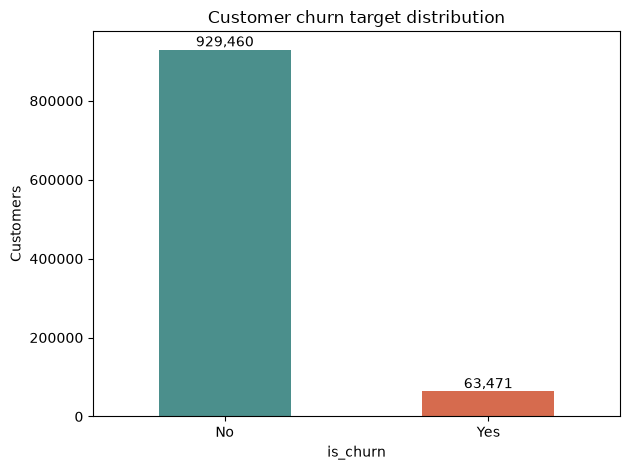

In [3]:
import matplotlib.pyplot as plt

churn_labels = ["No", "Yes"]
churn_colors = ["#4b8f8c", "#d66b4e"]

target_counts = y.map({0: "No", 1: "Yes"}).value_counts().reindex(churn_labels)
target_percentages = target_counts / len(df) * 100
imbalance_ratio = target_counts.max() / target_counts.min()
BASE_RATE = y.mean()

display(pd.DataFrame({"customers": target_counts, "percent": target_percentages.round(2)}))
print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}:1 | overall churn rate: {BASE_RATE:.2%}")

ax = target_counts.plot(kind="bar", color=churn_colors, rot=0)
ax.set(title="Customer churn target distribution", xlabel="is_churn", ylabel="Customers")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.tight_layout()
plt.savefig(GRAPHICS_DIR / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Numerical feature statistics

Count, mean, standard deviation and quantiles for every numeric feature. Many activity and payment aggregates
are heavily right-skewed, so the median and the 99th percentile are more informative than the mean and maximum.

In [4]:
summary = df[NUMERIC].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
summary.insert(0, "type", catalogue.loc[NUMERIC, "type"])
summary.insert(0, "domain", catalogue.loc[NUMERIC, "domain"])
display(summary.round(3))

,domain,type,count,mean,std,min,1%,25%,50%,75%,99%,max
bd_missing,member,binary,992931.0,0.608,0.488,0.000,0.000,0.000,1.000,1.000,1.000,1.000
has_member_record,member,binary,992931.0,0.883,0.321,0.000,0.000,1.000,1.000,1.000,1.000,1.000
is_cancel_change_flag,transactions,binary,990836.0,0.203,0.402,0.000,0.000,0.000,0.000,0.000,1.000,1.000
is_auto_renew_change_flag,transactions,binary,990836.0,0.900,0.300,0.000,0.000,1.000,1.000,1.000,1.000,1.000
autorenew_not_cancel,transactions,binary,990836.0,0.655,0.475,0.000,0.000,0.000,1.000,1.000,1.000,1.000
last_is_auto_renew,transactions,binary,990836.0,0.887,0.316,0.000,0.000,1.000,1.000,1.000,1.000,1.000
last_is_cancel,transactions,binary,990836.0,0.013,0.114,0.000,0.000,0.000,0.000,0.000,1.000,1.000
has_transactions,transactions,binary,992931.0,0.998,0.046,0.000,1.000,1.000,1.000,1.000,1.000,1.000
has_listening_logs,logs,binary,992931.0,0.814,0.389,0.000,0.000,1.000,1.000,1.000,1.000,1.000
registration_year,member,discrete,877161.0,2013.160,2.975,2004.000,2005.000,2012.000,2014.000,2016.000,2017.000,2017.000


## Takeaways

- **Imbalance.** The February cohort has 992,931 customers: 929,460 stay (93.61 %) and 63,471 churn (6.39 %), a
  14.64:1 majority-to-minority ratio. Always predicting "stay" would already be 93.6 % accurate, so accuracy is not
  used; the models are compared with log-loss, average precision and F1 on the churn class.
- **Feature groups.** 29 features come from transactions, 22 from the listening logs and 8 from the member table.
  By type: 38 continuous, 9 binary, 8 discrete, 3 nominal (`city`, `registered_via`, `last_payment_method_id`)
  and 1 constant.
- **Missing values.** Transaction statistics are null for about 0.2 % of customers (no transactions); `city`,
  `tenure_days` and the registration fields are null for 11.7 % (customers without a member record). The
  following notebooks keep these missing values and drop them pairwise in each measure.
- **Scope.** Everything is descriptive; associations are not causal effects.

---
**Previous:** `06_bivariate_raw.ipynb` · **Next:** `08_numeric_and_categorical_vs_churn.ipynb`